In [1]:
import pandas as pd

print("Notebook is ready!")
print("Pandas version:", pd.__version__)

Notebook is ready!
Pandas version: 3.0.6


In [4]:
from pathlib import Path

current_folder = Path.cwd()

print("Current folder:", current_folder)

Current folder: c:\Users\Sanket Patil\desktop\Payment-Transaction-Analytics-System\notebooks


In [5]:
from pathlib import Path
import sys

project_root = Path.cwd().parent

sys.path.insert(0, str(project_root))

print("Project root:", project_root)
print("src folder exists:", (project_root / "src").is_dir())

Project root: c:\Users\Sanket Patil\desktop\Payment-Transaction-Analytics-System
src folder exists: True


In [6]:
from src.analysis.common import load_project_csv

transactions = load_project_csv("transactions.csv")

print("CSV loaded successfully!")
print("Rows and columns:", transactions.shape)

transactions.head()

CSV loaded successfully!
Rows and columns: (10000, 12)


,transaction_id,customer_id,merchant_id,payment_method_id,transaction_date,amount,currency,transaction_status,transaction_type,channel,city,state
0,TXN000001,CUST03136,MER03212,PM03707,2024-04-30 03:34:18,3497.58,INR,Success,Purchase,Mobile,Surat,Gujarat
1,TXN000002,CUST00249,MER04184,PM00989,2024-02-27 13:04:30,37124.66,INR,Success,Purchase,Mobile,Indore,Madhya Pradesh
2,TXN000003,CUST00727,MER03163,PM09518,2024-04-02 11:37:37,77539.12,INR,Success,Purchase,Mobile,Noida,UTTAR PRADESH
3,TXN000004,CUST07626,MER07052,PM08428,2024-07-20 23:39:05,78020.60,INR,Success,Purchase,Mobile,Chennai,Tamil Nadu
4,TXN000005,CUST04408,MER00136,PM00601,2024-07-12 09:45:01,43944.68,INR,success,Purchase,POS,Bengaluru,Karnataka


In [13]:
from src.analysis.common import require_columns
required_columns = ["transaction_id", "amount", "transaction_status"]
require_columns(transactions, required_columns, "transactions.csv")
print("required column check complete")


required column check complete


In [14]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [23]:

from pathlib import Path
import sys

current_folder = Path.cwd()

# Find project root using data/raw
project_root = next(
    (
        folder
        for folder in [current_folder, *current_folder.parents]
        if (folder / "data" / "raw").is_dir()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Project root not found. Check the data/raw folder."
    )

# Locate the existing common.py file
common_file = project_root / "src" / "analysis" / "common.py"

if not common_file.is_file():
    raise FileNotFoundError(
        f"common.py not found: {common_file}"
    )

# Add the module directory to Python's import path
analysis_folder = str(common_file.parent)

if analysis_folder not in sys.path:
    sys.path.insert(0, analysis_folder)

print("Project root:", project_root)
print("Common file:", common_file)


Project root: c:\Users\Sanket Patil\desktop\Payment-Transaction-Analytics-System
Common file: c:\Users\Sanket Patil\desktop\Payment-Transaction-Analytics-System\src\analysis\common.py


In [24]:

from common import (
    load_project_csv,
    require_columns,
    save_report
)

print("Common functions imported successfully!")



Common functions imported successfully!


In [25]:

payment_methods = load_project_csv("payment_methods.csv")
transactions = load_project_csv("transactions.csv")

print("Payment Methods Shape:", payment_methods.shape)
print("Transactions Shape:", transactions.shape)

display(payment_methods.head())
display(transactions.head())


Payment Methods Shape: (10000, 7)
Transactions Shape: (10000, 12)


,payment_method_id,customer_id,method_type,provider,last_four_digits,is_default,created_date
0,PM00001,CUST07008,Net Banking,ICICI Bank,6211.0,true,2024-12-19
1,PM00002,CUST03088,Debit Card,HDFC Bank,6337.0,false,2024-07-25
2,PM00003,CUST04595,Net Banking,SBI,3686.0,false,2023-06-07
3,PM00004,CUST05188,Debit Card,SBI,773.0,NaN,2024-04-12
4,NaN,CUST05725,Debit Card,SBI,8439.0,true,2024-10-31


,transaction_id,customer_id,merchant_id,payment_method_id,transaction_date,amount,currency,transaction_status,transaction_type,channel,city,state
0,TXN000001,CUST03136,MER03212,PM03707,2024-04-30 03:34:18,3497.58,INR,Success,Purchase,Mobile,Surat,Gujarat
1,TXN000002,CUST00249,MER04184,PM00989,2024-02-27 13:04:30,37124.66,INR,Success,Purchase,Mobile,Indore,Madhya Pradesh
2,TXN000003,CUST00727,MER03163,PM09518,2024-04-02 11:37:37,77539.12,INR,Success,Purchase,Mobile,Noida,UTTAR PRADESH
3,TXN000004,CUST07626,MER07052,PM08428,2024-07-20 23:39:05,78020.60,INR,Success,Purchase,Mobile,Chennai,Tamil Nadu
4,TXN000005,CUST04408,MER00136,PM00601,2024-07-12 09:45:01,43944.68,INR,success,Purchase,POS,Bengaluru,Karnataka


In [27]:
"""Validate payment methods and transaction datasets."""
class PaymentDataValidator:
    
    def __init__(self, payment_methods, transactions):
        self.payment_methods = payment_methods
        self.transactions = transactions

    def validate_columns(self):
        """Check required columns in both datasets."""

        require_columns(
            self.payment_methods,
            ["payment_method_id", "method_type", "provider",
             "customer_id", "is_default"],
            "payment_methods"
        )

        require_columns(
            self.transactions,
            ["customer_id", "payment_method_id",
             "amount", "transaction_status"],
            "transactions"
        )

        print("Required columns validation passed.")

    def show_dataset_info(self):
        """Display basic information about both datasets."""

        for name, data in [
            ("Payment Methods", self.payment_methods),
            ("Transactions", self.transactions)
        ]:
            print(f"\n{name}")
            print("-" * 40)
            print("Rows and columns:", data.shape)
            print("Column names:", data.columns.tolist())
            print("\nMissing values:")
            print(data.isnull().sum())


In [28]:

validator = PaymentDataValidator(
    payment_methods=payment_methods,
    transactions=transactions
)

validator.validate_columns()
validator.show_dataset_info()


Required columns validation passed.

Payment Methods
----------------------------------------
Rows and columns: (10000, 7)
Column names: ['payment_method_id', 'customer_id', 'method_type', 'provider', 'last_four_digits', 'is_default', 'created_date']

Missing values:
payment_method_id    148
customer_id          151
method_type          149
provider             150
last_four_digits     151
is_default           170
created_date         150
dtype: int64

Transactions
----------------------------------------
Rows and columns: (10000, 12)
Column names: ['transaction_id', 'customer_id', 'merchant_id', 'payment_method_id', 'transaction_date', 'amount', 'currency', 'transaction_status', 'transaction_type', 'channel', 'city', 'state']

Missing values:
transaction_id        151
customer_id           200
merchant_id           197
payment_method_id     197
transaction_date      151
amount                202
currency              149
transaction_status    149
transaction_type      149
channel     

In [32]:

class PaymentDataCleaner:
    """Clean payment method and transaction status values."""

    def __init__(self, payment_methods, transactions):
        self.payment_methods = payment_methods.copy()
        self.transactions = transactions.copy()

    def clean_default_status(self):
        """Normalize is_default values using the original mapping."""

        self.payment_methods["is_default"] = (
            self.payment_methods["is_default"]
            .astype(str)
            .str.strip()
            .str.lower()
            .map({
                "true": "True",
                "false": "False",
                "0": "True",
                "yes": "True",
                "1": "False",
                "flase": "False",
                "no": "False"
            })
        )

        return self.payment_methods

    def clean_transaction_status(self):
        """Standardize transaction status capitalization."""

        self.transactions["transaction_status"] = (
            self.transactions["transaction_status"]
            .astype("string")
            .str.strip()
            .str.capitalize()
        )

        return self.transactions

    def clean_all(self):
        """Run the existing cleaning steps."""

        self.clean_default_status()
        self.clean_transaction_status()

        return self.payment_methods, self.transactions


In [33]:

cleaner = PaymentDataCleaner(
    payment_methods=payment_methods,
    transactions=transactions
)

payment_methods_clean, transactions_clean = cleaner.clean_all()

print("Default payment method values:")
print(payment_methods_clean["is_default"].value_counts(dropna=False))

print("\nTransaction status values:")
print(transactions_clean["transaction_status"].value_counts(dropna=False))


Default payment method values:
is_default
True     7597
False    2233
NaN       170
Name: count, dtype: int64

Transaction status values:
transaction_status
Success    8117
Failed     1163
Pending     571
<NA>        149
Name: count, dtype: Int64


In [36]:
class PaymentTransactionAnalysis:
    """Merge payment methods and transactions datasets."""

    def __init__(self, payment_methods, transactions):
        self.payment_methods = payment_methods.copy()
        self.transactions = transactions.copy()
        self.payment_analysis = None

    def merge_datasets(self):
        """Merge datasets using payment_method_id."""

        self.payment_analysis = self.transactions.merge(
            self.payment_methods,
            on="payment_method_id",
            how="left"
        )

        return self.payment_analysis



In [37]:
analysis = PaymentTransactionAnalysis(
    payment_methods=payment_methods_clean,
    transactions=transactions_clean
)

payment_analysis = analysis.merge_datasets()

print("Merged dataset shape:", payment_analysis.shape)
display(payment_analysis.head())

Merged dataset shape: (39073, 18)


,transaction_id,customer_id_x,merchant_id,payment_method_id,transaction_date,amount,currency,transaction_status,transaction_type,channel,city,state,customer_id_y,method_type,provider,last_four_digits,is_default,created_date
0,TXN000001,CUST03136,MER03212,PM03707,2024-04-30 03:34:18,3497.58,INR,Success,Purchase,Mobile,Surat,Gujarat,CUST05380,UPI,PhonePe,3278.0,True,2023-11-14
1,TXN000002,CUST00249,MER04184,PM00989,2024-02-27 13:04:30,37124.66,INR,Success,Purchase,Mobile,Indore,Madhya Pradesh,CUST07797,UPI,PhonePe,4594.0,True,2023-12-09
2,TXN000003,CUST00727,MER03163,PM09518,2024-04-02 11:37:37,77539.12,INR,Success,Purchase,Mobile,Noida,UTTAR PRADESH,CUST00944,UPI,PhonePe,7833.0,True,2025-03-29
3,TXN000004,CUST07626,MER07052,PM08428,2024-07-20 23:39:05,78020.60,INR,Success,Purchase,Mobile,Chennai,Tamil Nadu,CUST03606,Credit Card,HDFC Bank,4217.0,NaN,2023-04-17
4,TXN000005,CUST04408,MER00136,PM00601,2024-07-12 09:45:01,43944.68,INR,Success,Purchase,POS,Bengaluru,Karnataka,NaN,NaN,NaN,NaN,NaN,NaN


In [39]:
class PaymentMethodMetrics:
    """Calculate transaction metrics for each payment method."""

    def __init__(self, payment_analysis):
        self.payment_analysis = payment_analysis.copy()
        self.transaction_count = None

    def transaction_count_by_method(self):
        """Count transactions by payment method."""

        self.transaction_count = (
            self.payment_analysis
            .groupby("method_type")["payment_method_id"]
            .count()
            .sort_values(ascending=False)
        )

        print("Transaction count by payment method:")
        display(self.transaction_count)

        return self.transaction_count

    def transaction_amount_by_method(self):
        """Calculate total transaction amount by payment method."""

        transaction_amount = (
            self.payment_analysis
            .groupby("method_type")["amount"]
            .sum()
            .sort_values(ascending=False)
        )

        print("Total transaction amount by payment method:")
        display(transaction_amount.round(2))

        return transaction_amount

    def transaction_percentage_by_method(self):
        """Calculate percentage of transactions by payment method."""

        if self.transaction_count is None:
            self.transaction_count_by_method()

        transaction_percentage = (
            self.transaction_count / self.transaction_count.sum()
        ) * 100

        print("Transaction percentage by payment method:")
        display(transaction_percentage.round(2))

        return transaction_percentage

    def average_transaction_amount(self):
        """Calculate average transaction amount by payment method."""

        average_amount = (
            self.payment_analysis
            .groupby("method_type")["amount"]
            .mean()
            .sort_values(ascending=False)
        )

        print("Average transaction amount by payment method:")
        display(average_amount.round(2))

        return average_amount

    def most_and_least_used_methods(self):
        """Find the most and least frequently used payment methods."""

        most_used = self.payment_analysis["method_type"].value_counts()

        print("Most frequently used payment method:")
        display(most_used.head(1))

        print("Least frequently used payment method:")
        display(most_used.tail(1))

        return most_used.head(1), most_used.tail(1)

In [40]:
metrics = PaymentMethodMetrics(payment_analysis)

transaction_count = metrics.transaction_count_by_method()

transaction_amount = metrics.transaction_amount_by_method()

transaction_percentage = metrics.transaction_percentage_by_method()

average_amount = metrics.average_transaction_amount()

most_used, least_used = metrics.most_and_least_used_methods()

Transaction count by payment method:


method_type
UPI            4520
Credit Card    2011
Debit Card     2002
Net Banking     912
Name: payment_method_id, dtype: int64

Total transaction amount by payment method:


method_type
UPI            4.602210e+08
Credit Card    2.077930e+08
Debit Card     1.532660e+08
Net Banking    1.135898e+08
Name: amount, dtype: float64

Transaction percentage by payment method:


...

method_type
Credit Card    25026.25
Net Banking    24975.76
UPI            24965.88
Debit Card     24752.27
Name: amount, dtype: float64

Most frequently used payment method:


method_type
UPI    18901
Name: count, dtype: int64

Least frequently used payment method:


method_type
Net Banking    4655
Name: count, dtype: int64

In [41]:
class TransactionStatusAnalyzer:
    """Analyze successful and failed transactions by payment method."""

    def __init__(self, payment_analysis):
        self.payment_analysis = payment_analysis.copy()
        self.success_count = None
        self.failed_count = None
        self.total_by_method = None

    def check_transaction_status(self):
        """Display transaction status counts."""

        print("Transaction status counts:")
        display(
            self.payment_analysis["transaction_status"].value_counts()
        )

    def successful_transactions_by_method(self):
        """Count successful transactions by payment method."""

        successful_transactions = self.payment_analysis[
            self.payment_analysis["transaction_status"] == "Success"
        ]

        self.success_count = (
            successful_transactions
            .groupby("method_type")
            .size()
            .sort_values(ascending=False)
        )

        print("Successful transactions by payment method:")
        display(self.success_count)

        return self.success_count

    def failed_transactions_by_method(self):
        """Count failed transactions by payment method."""

        failed_transactions = self.payment_analysis[
            self.payment_analysis["transaction_status"] == "Failed"
        ]

        self.failed_count = (
            failed_transactions
            .groupby("method_type")
            .size()
            .sort_values(ascending=False)
        )

        print("Failed transactions by payment method:")
        display(self.failed_count)

        return self.failed_count

    def success_rate_by_method(self):
        """Calculate success rate for each payment method."""

        if self.success_count is None:
            self.successful_transactions_by_method()

        self.total_by_method = (
            self.payment_analysis.groupby("method_type").size()
        )

        success_rate = (
            self.success_count / self.total_by_method
        ) * 100

        print("Success rate by payment method (%):")
        display(success_rate.round(2).sort_values(ascending=False))

        return success_rate

    def failure_rate_by_method(self):
        """Calculate failure rate for each payment method."""

        if self.failed_count is None:
            self.failed_transactions_by_method()

        if self.total_by_method is None:
            self.total_by_method = (
                self.payment_analysis.groupby("method_type").size()
            )

        failure_rate = (
            self.failed_count / self.total_by_method
        ) * 100

        print("Failure rate by payment method (%):")
        display(failure_rate.round(2).sort_values(ascending=False))

        return failure_rate

In [42]:
status_analyzer = TransactionStatusAnalyzer(payment_analysis)

status_analyzer.check_transaction_status()

success_count = status_analyzer.successful_transactions_by_method()

failed_count = status_analyzer.failed_transactions_by_method()

success_rate = status_analyzer.success_rate_by_method()

failure_rate = status_analyzer.failure_rate_by_method()

Transaction status counts:


transaction_status
Success    31138
Failed      5738
Pending     1752
Name: count, dtype: Int64

Successful transactions by payment method:


method_type
UPI            15047
Credit Card     6764
Debit Card      5068
Net Banking     3704
dtype: int64

Failed transactions by payment method:


method_type
UPI            2798
Credit Card    1259
Debit Card      909
Net Banking     693
dtype: int64

Success rate by payment method (%):


method_type
Debit Card     79.99
UPI            79.61
Net Banking    79.57
Credit Card    79.46
dtype: float64

Failure rate by payment method (%):


method_type
Net Banking    14.89
UPI            14.80
Credit Card    14.79
Debit Card     14.35
dtype: float64

In [43]:

class TransactionAmountAnalyzer:
    """Analyze transaction amounts by status and payment method."""

    def __init__(self, payment_analysis):
        self.payment_analysis = payment_analysis.copy()

    def normalize_transaction_status(self):
        """Convert transaction status to lowercase and remove extra spaces."""

        self.payment_analysis["transaction_status"] = (
            self.payment_analysis["transaction_status"]
            .astype("string")
            .str.strip()
            .str.lower()
        )

        print("Transaction status counts:")
        display(
            self.payment_analysis["transaction_status"]
            .value_counts(dropna=False)
        )

        return self.payment_analysis

    def amount_by_status_and_method(self):
        """Calculate total transaction amount by status and payment method."""

        amount_by_status_method = (
            self.payment_analysis
            .groupby(["method_type", "transaction_status"])["amount"]
            .sum()
            .unstack(fill_value=0)
        )

        print("Total amount by status and payment method:")
        display(amount_by_status_method)

        return amount_by_status_method


In [44]:

amount_analyzer = TransactionAmountAnalyzer(payment_analysis)

payment_analysis = amount_analyzer.normalize_transaction_status()

amount_by_status_method = amount_analyzer.amount_by_status_and_method()


Transaction status counts:


transaction_status
success    31138
failed      5738
pending     1752
<NA>         445
Name: count, dtype: Int64

Total amount by status and payment method:


transaction_status,failed,pending,success
method_type,,,
Credit Card,27363587.11,8677246.87,1.672338e+08
Debit Card,20569970.75,5715240.73,1.240671e+08
Net Banking,15084568.05,4331325.59,9.186218e+07
UPI,62275843.26,17322594.19,3.714851e+08


In [46]:

class ProviderTransactionAnalyzer:
    """Analyze transaction volume and amount by provider."""

    def __init__(self, payment_analysis):
        self.payment_analysis = payment_analysis.copy()

    def transactions_by_provider(self):
        """Count transactions for each provider."""

        transaction_by_provider = (
            self.payment_analysis
            .groupby("provider")["method_type"]
            .count()
            .sort_values(ascending=False)
        )

        print("Transactions by provider:")
        display(transaction_by_provider)

        return transaction_by_provider

    def transaction_amount_by_provider(self):
        """Calculate total transaction amount for each provider."""

        transaction_amount = (
            self.payment_analysis
            .groupby("provider")["amount"]
            .sum()
            .sort_values(ascending=False)
        )

        print("Total transaction amount by provider:")
        display(transaction_amount.round(2))

        return transaction_amount

    def success_failure_by_provider(self):
        """Count successful and failed transactions for each provider."""

        provider_status = pd.crosstab(
            self.payment_analysis["provider"],
            self.payment_analysis["transaction_status"]
        )

        print("Success and failure analysis by provider:")
        display(provider_status)

        return provider_status


In [47]:

provider_analyzer = ProviderTransactionAnalyzer(payment_analysis)

transaction_by_provider = provider_analyzer.transactions_by_provider()

transaction_amount_by_provider = (
    provider_analyzer.transaction_amount_by_provider()
)

provider_status = provider_analyzer.success_failure_by_provider()


Transactions by provider:


provider
ICICI Bank    5439
SBI           5436
PhonePe       5399
Paytm         5273
HDFC Bank     4982
GooglePay     4070
BHIM          3894
Axis Bank     3174
Name: method_type, dtype: int64

Total transaction amount by provider:


provider
ICICI Bank    1.332340e+08
SBI           1.330421e+08
PhonePe       1.329664e+08
Paytm         1.288237e+08
HDFC Bank     1.213758e+08
GooglePay     1.030924e+08
BHIM          9.477232e+07
Axis Bank     7.676198e+07
Name: amount, dtype: float64

Success and failure analysis by provider:


transaction_status,failed,pending,success
provider,,,
Axis Bank,455,131,2554
BHIM,580,182,3094
GooglePay,631,193,3409
HDFC Bank,740,235,3973
ICICI Bank,808,260,4338
Paytm,787,238,4210
PhonePe,800,221,4323
SBI,799,244,4353


In [48]:

class ProviderPerformanceAnalyzer:
    """Analyze overall transaction performance for each provider."""

    def __init__(self, payment_analysis):
        self.payment_analysis = payment_analysis.copy()

    def analyze_provider_performance(self):
        """Calculate transaction metrics and success/failure rates."""

        provider_performance = (
            self.payment_analysis
            .groupby("provider")
            .agg(
                total_transactions=("payment_method_id", "count"),
                total_amount=("amount", "sum"),
                average_amount=("amount", "mean")
            )
        )

        provider_performance["success_count"] = (
            self.payment_analysis[
                self.payment_analysis["transaction_status"] == "success"
            ]
            .groupby("provider")["payment_method_id"]
            .count()
        )

        provider_performance["failure_count"] = (
            self.payment_analysis[
                self.payment_analysis["transaction_status"] == "failed"
            ]
            .groupby("provider")["payment_method_id"]
            .count()
        )

        provider_performance = provider_performance.fillna(0)

        provider_performance["success_rate"] = (
            provider_performance["success_count"]
            / provider_performance["total_transactions"]
            * 100
        )

        provider_performance["failure_rate"] = (
            provider_performance["failure_count"]
            / provider_performance["total_transactions"]
            * 100
        )

        print("Provider Performance Analysis:")
        display(provider_performance.round(2))

        return provider_performance


In [49]:

provider_performance_analyzer = ProviderPerformanceAnalyzer(
    payment_analysis
)

provider_performance = (
    provider_performance_analyzer.analyze_provider_performance()
)


Provider Performance Analysis:


,total_transactions,total_amount,average_amount,success_count,failure_count,success_rate,failure_rate
provider,,,,,,,
Axis Bank,1013,7.676198e+07,24674.38,838,114,82.72,11.25
BHIM,1145,9.477232e+07,24881.16,910,146,79.48,12.75
GooglePay,1129,1.030924e+08,24675.06,913,135,80.87,11.96
HDFC Bank,1260,1.213758e+08,24846.64,1009,151,80.08,11.98
ICICI Bank,1329,1.332340e+08,25011.07,1062,157,79.91,11.81
Paytm,1157,1.288237e+08,24990.04,934,136,80.73,11.75
PhonePe,1074,1.329664e+08,25192.58,891,118,82.96,10.99
SBI,1320,1.330421e+08,24932.93,1077,148,81.59,11.21


In [51]:

class PaymentDataQualityChecker:
    """Perform data quality checks on payment and transaction data."""

    def __init__(self, transactions, payment_methods):
        self.transactions = transactions.copy()
        self.payment_methods = payment_methods.copy()

    def check_missing_ids(self):
        """Count missing payment method IDs."""

        print(
            "Missing IDs in transactions:",
            self.transactions["payment_method_id"].isnull().sum()
        )

        print(
            "Missing IDs in payment_methods:",
            self.payment_methods["payment_method_id"].isnull().sum()
        )

    def check_unmatched_ids(self):
        """Find transaction IDs not present in payment_methods."""

        missing_ids = self.transactions[
            ~self.transactions["payment_method_id"].isin(
                self.payment_methods["payment_method_id"]
            )
        ]

        print("Total unmatched transactions:", len(missing_ids))

        return missing_ids

    def check_duplicate_ids(self):
        """Find duplicate payment method IDs."""

        duplicate_payment_ids = self.payment_methods[
            self.payment_methods["payment_method_id"].duplicated(
                keep=False
            )
        ]

        print(
            "Total duplicated IDs:",
            len(duplicate_payment_ids)
        )

        return duplicate_payment_ids

    def check_missing_method_types(self):
        """Count missing payment method types."""

        print(
            "Total missing method types:",
            self.payment_methods["method_type"].isnull().sum()
        )

    def check_missing_providers(self):
        """Count missing providers."""

        print(
            "Total missing providers:",
            self.payment_methods["provider"].isnull().sum()
        )

    def check_unique_values(self):
        """Display method type and provider value counts."""

        print("Unique method types:")
        display(
            self.payment_methods["method_type"].value_counts(
                dropna=False
            )
        )

        print("Unique providers:")
        display(
            self.payment_methods["provider"].value_counts(
                dropna=False
            )
        )


In [52]:

quality_checker = PaymentDataQualityChecker(
    transactions,
    payment_methods
)

quality_checker.check_missing_ids()

missing_ids = quality_checker.check_unmatched_ids()

duplicate_payment_ids = quality_checker.check_duplicate_ids()

quality_checker.check_missing_method_types()

quality_checker.check_missing_providers()

quality_checker.check_unique_values()


Missing IDs in transactions: 197
Missing IDs in payment_methods: 148
Total unmatched transactions: 344
Total duplicated IDs: 382
Total missing method types: 149
Total missing providers: 150
Unique method types:


method_type
UPI            4679
Credit Card    2168
Debit Card     1999
Net Banking    1005
NaN             149
Name: count, dtype: int64

Unique providers:


provider
ICICI Bank    1380
HDFC Bank     1369
SBI           1364
Paytm         1224
GooglePay     1174
BHIM          1146
PhonePe       1142
Axis Bank     1051
NaN            150
Name: count, dtype: int64

In [54]:

class PaymentAnalyticsVisualizer:
    """Visualize payment method and transaction performance."""

    def __init__(self, payment_analysis):
        self.payment_analysis = payment_analysis.copy()

    def plot_transaction_count(self):
        """Transaction count by payment method."""

        method_transactions = (
            self.payment_analysis
            .groupby("method_type")
            .size()
            .sort_values(ascending=False)
        )

        plt.figure(figsize=(8, 5))
        sns.barplot(
            x=method_transactions.index,
            y=method_transactions.values
        )

        plt.title("Transaction Count by Payment Method")
        plt.xlabel("Payment Method")
        plt.ylabel("Number of Transactions")
        plt.tight_layout()
        plt.show()

    def plot_transaction_amount(self):
        """Total transaction value by payment method."""

        method_amount = (
            self.payment_analysis
            .groupby("method_type")["amount"]
            .sum()
            .sort_values(ascending=False)
        )

        plt.figure(figsize=(8, 5))
        sns.barplot(
            x=method_amount.index,
            y=method_amount.values
        )

        plt.title("Total Transaction Value by Payment Method")
        plt.xlabel("Payment Method")
        plt.ylabel("Total Transaction Amount")
        plt.tight_layout()
        plt.show()

    def plot_status_by_method(self):
        """Compare successful and failed transactions by method."""

        self.payment_analysis["transaction_status"] = (
            self.payment_analysis["transaction_status"]
            .astype("string")
            .str.strip()
            .str.lower()
        )

        status_method = pd.crosstab(
            self.payment_analysis["method_type"],
            self.payment_analysis["transaction_status"]
        )

        status_method.plot(kind="bar", figsize=(9, 5))

        plt.title("Transaction Status by Payment Method")
        plt.xlabel("Payment Method")
        plt.ylabel("Number of Transactions")
        plt.legend(title="Transaction Status")
        plt.tight_layout()
        plt.show()

    def plot_provider_success_rate(self):
        """Compare success rates across providers."""

        provider_total = (
            self.payment_analysis.groupby("provider").size()
        )

        provider_success = (
            self.payment_analysis[
                self.payment_analysis["transaction_status"] == "success"
            ]
            .groupby("provider")
            .size()
        )

        provider_success_rate = (
            provider_success / provider_total * 100
        ).fillna(0).sort_values(ascending=False)

        plt.figure(figsize=(9, 5))
        sns.barplot(
            x=provider_success_rate.index,
            y=provider_success_rate.values
        )

        plt.title("Success Rate by Provider")
        plt.xlabel("Provider")
        plt.ylabel("Success Rate (%)")
        plt.tight_layout()
        plt.show()

    def plot_average_amount(self):
        """Average transaction amount by payment method."""

        avg_amount = (
            self.payment_analysis
            .groupby("method_type")["amount"]
            .mean()
            .sort_values(ascending=False)
        )

        plt.figure(figsize=(8, 5))
        sns.barplot(
            x=avg_amount.index,
            y=avg_amount.values
        )

        plt.title("Average Transaction Amount by Payment Method")
        plt.xlabel("Payment Method")
        plt.ylabel("Average Transaction Amount")
        plt.tight_layout()
        plt.show()

    def plot_method_transaction_share(self):
        """Show transaction share for each payment method."""

        method_counts = (
            self.payment_analysis["method_type"].value_counts()
        )

        plt.figure(figsize=(7, 7))
        plt.pie(
            method_counts.values,
            labels=method_counts.index,
            autopct="%1.1f%%",
            startangle=90
        )

        plt.title("Payment Method wise Transaction Share")
        plt.show()

    def plot_overall_transaction_status(self):
        """Show the overall distribution of transaction statuses."""

        status_counts = (
            self.payment_analysis["transaction_status"].value_counts()
        )

        plt.figure(figsize=(7, 7))
        plt.pie(
            status_counts.values,
            labels=status_counts.index,
            autopct="%1.1f%%",
            startangle=90
        )

        plt.title("Overall Transaction Status")
        plt.show()

    def plot_average_amount_line(self):
        """Line plot of average transaction amount by payment method."""

        avg_method_amount = (
            self.payment_analysis
            .groupby("method_type")["amount"]
            .mean()
        )

        plt.figure(figsize=(8, 5))
        plt.plot(
            avg_method_amount.index,
            avg_method_amount.values,
            marker="o"
        )

        plt.title("Average Transaction Amount by Payment Method")
        plt.xlabel("Payment Method")
        plt.ylabel("Average Transaction Amount")
        plt.grid(True)
        plt.tight_layout()
        plt.show()


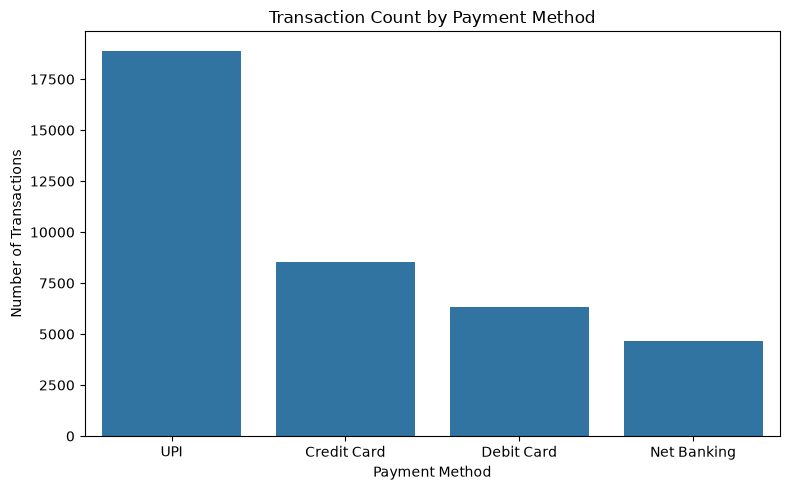

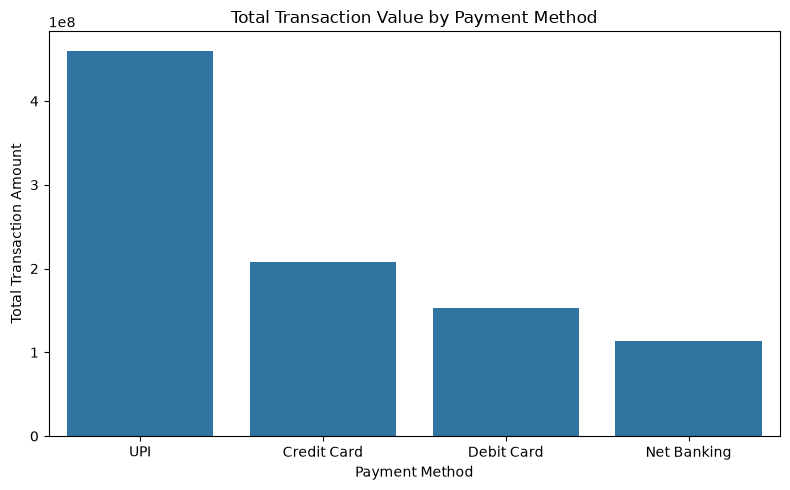

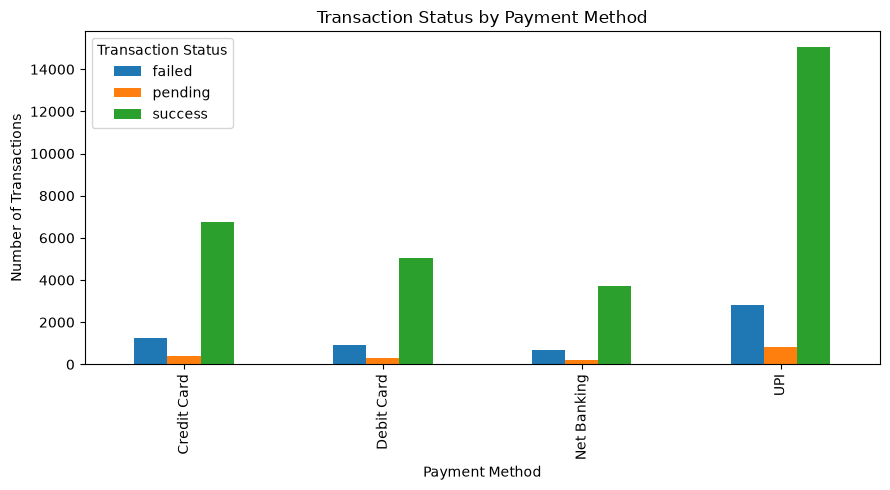

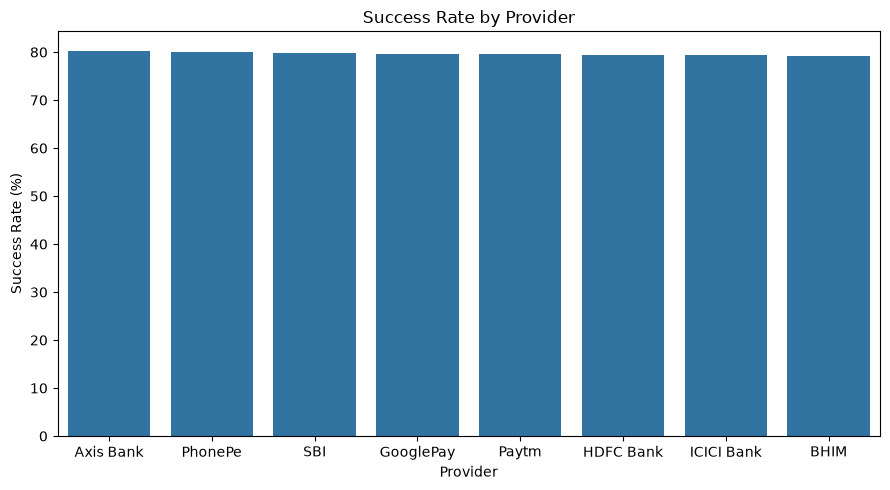

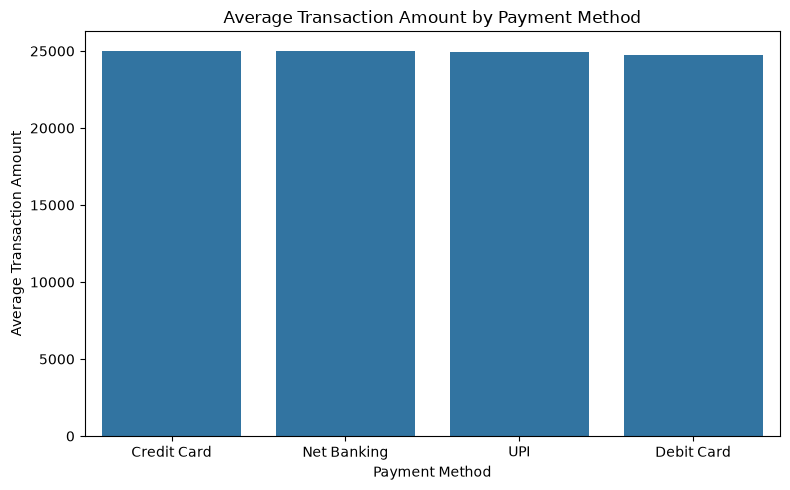

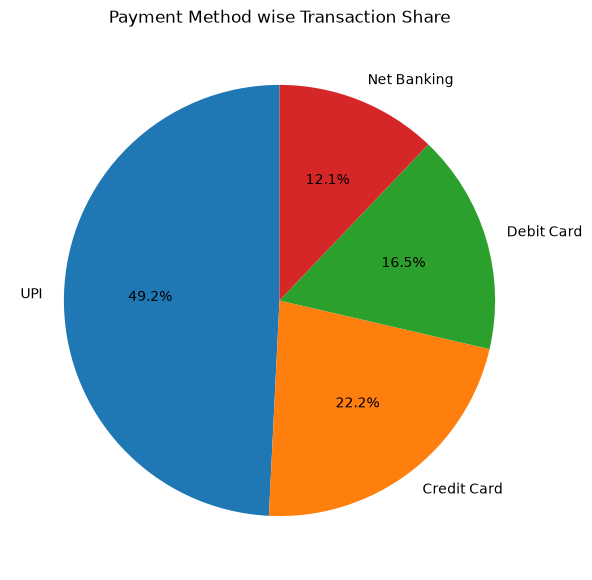

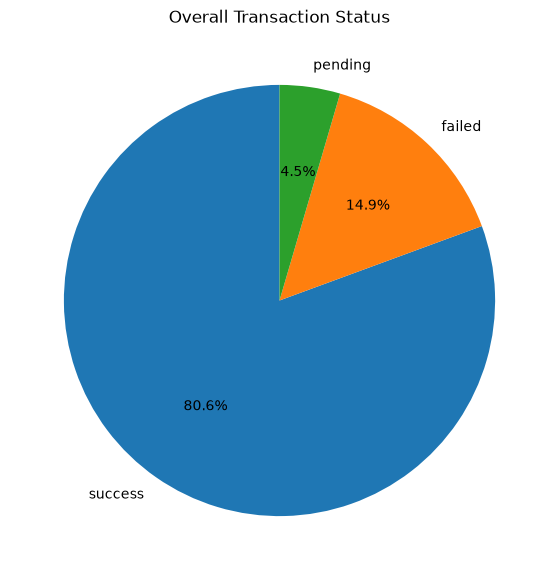

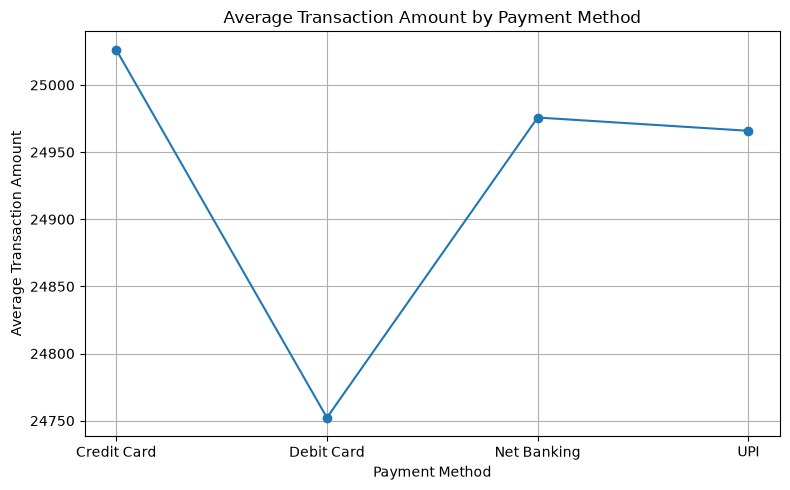

In [55]:

visualizer = PaymentAnalyticsVisualizer(payment_analysis)

visualizer.plot_transaction_count()

visualizer.plot_transaction_amount()

visualizer.plot_status_by_method()

visualizer.plot_provider_success_rate()

visualizer.plot_average_amount()

visualizer.plot_method_transaction_share()

visualizer.plot_overall_transaction_status()

visualizer.plot_average_amount_line()
